## Question 1

In [89]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [90]:
# Load image
im = cv.imread(r"C:\Users\USER\Desktop\UNI\Semesters\Semester 5\Machine_Vision\New folder\Image-Processing-and-Machine-Vision-Assignment_02\a2images\the_berry_farms_sunflower_field.jpeg", cv.IMREAD_REDUCED_COLOR_4)
assert im is not None

# Get grayscale image
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)

In [91]:
# Select range of sigma
sigma_values = np.linspace(1, 2, 3)
# Threhsold for blob detection
threshold = 0.35

# Store responses of each scale
blob_responses = []

for sigma in sigma_values:
    print(f"Processing scale with sigma = {sigma}")

    # Apply Gaussian blur
    gaussian_blur = cv.GaussianBlur(gray, (0, 0), sigma)
    # Compute Laplacian of Gaussian (LoG)
    laplacian = cv.Laplacian(gaussian_blur, cv.CV_64F)

    # Get absolute value
    blob_response = sigma**2 * np.abs(laplacian)

    # Threshold the response and get contours
    mask = blob_response > threshold * blob_response.max()
    contours, _ = cv.findContours(mask.astype(np.uint8), cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

    # Draw contours as circles
    for contour in contours:
        if len(contour) >= 5:
            # Get the center and radius of the enclosing circle from contour
            (center_x, center_y), radius = cv.minEnclosingCircle(contour)
            # Convert to integers
            center = (int(center_x), int(center_y))
            radius = int(radius)
            blob_responses.append((center, radius, sigma))

Processing scale with sigma = 1.0
Processing scale with sigma = 1.5
Processing scale with sigma = 2.0


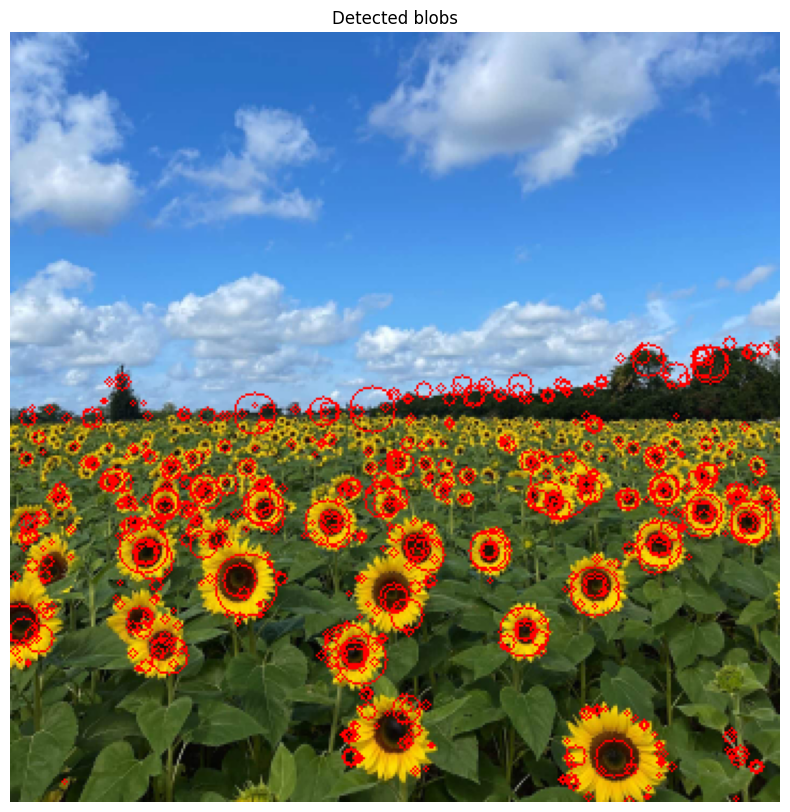

In [92]:
# Draw all detected circles with the specified line thickness
#output = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)

output = im.copy()
for blob in blob_responses:
    center, radius, _ = blob
    cv.circle(output, center, radius, (0,0,255), 1)

# Display the grayscale image with detected circles
plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB), cmap='gray')
plt.axis('off')
plt.title('Detected blobs')
plt.show()

## Question 2

Line inliers: 54
Best-fit line [a, b, d]: [0.71814154 0.69589707 1.52220339]
Normal vector length: 1.0
Circle RANSAC inliers: 38
Circle from best sample: [1.82378134 3.17707061 9.89821879]
Final circle [x0, y0, radius]: [1.82118463 3.21671758 9.91560013]
Final circle inliers: 38


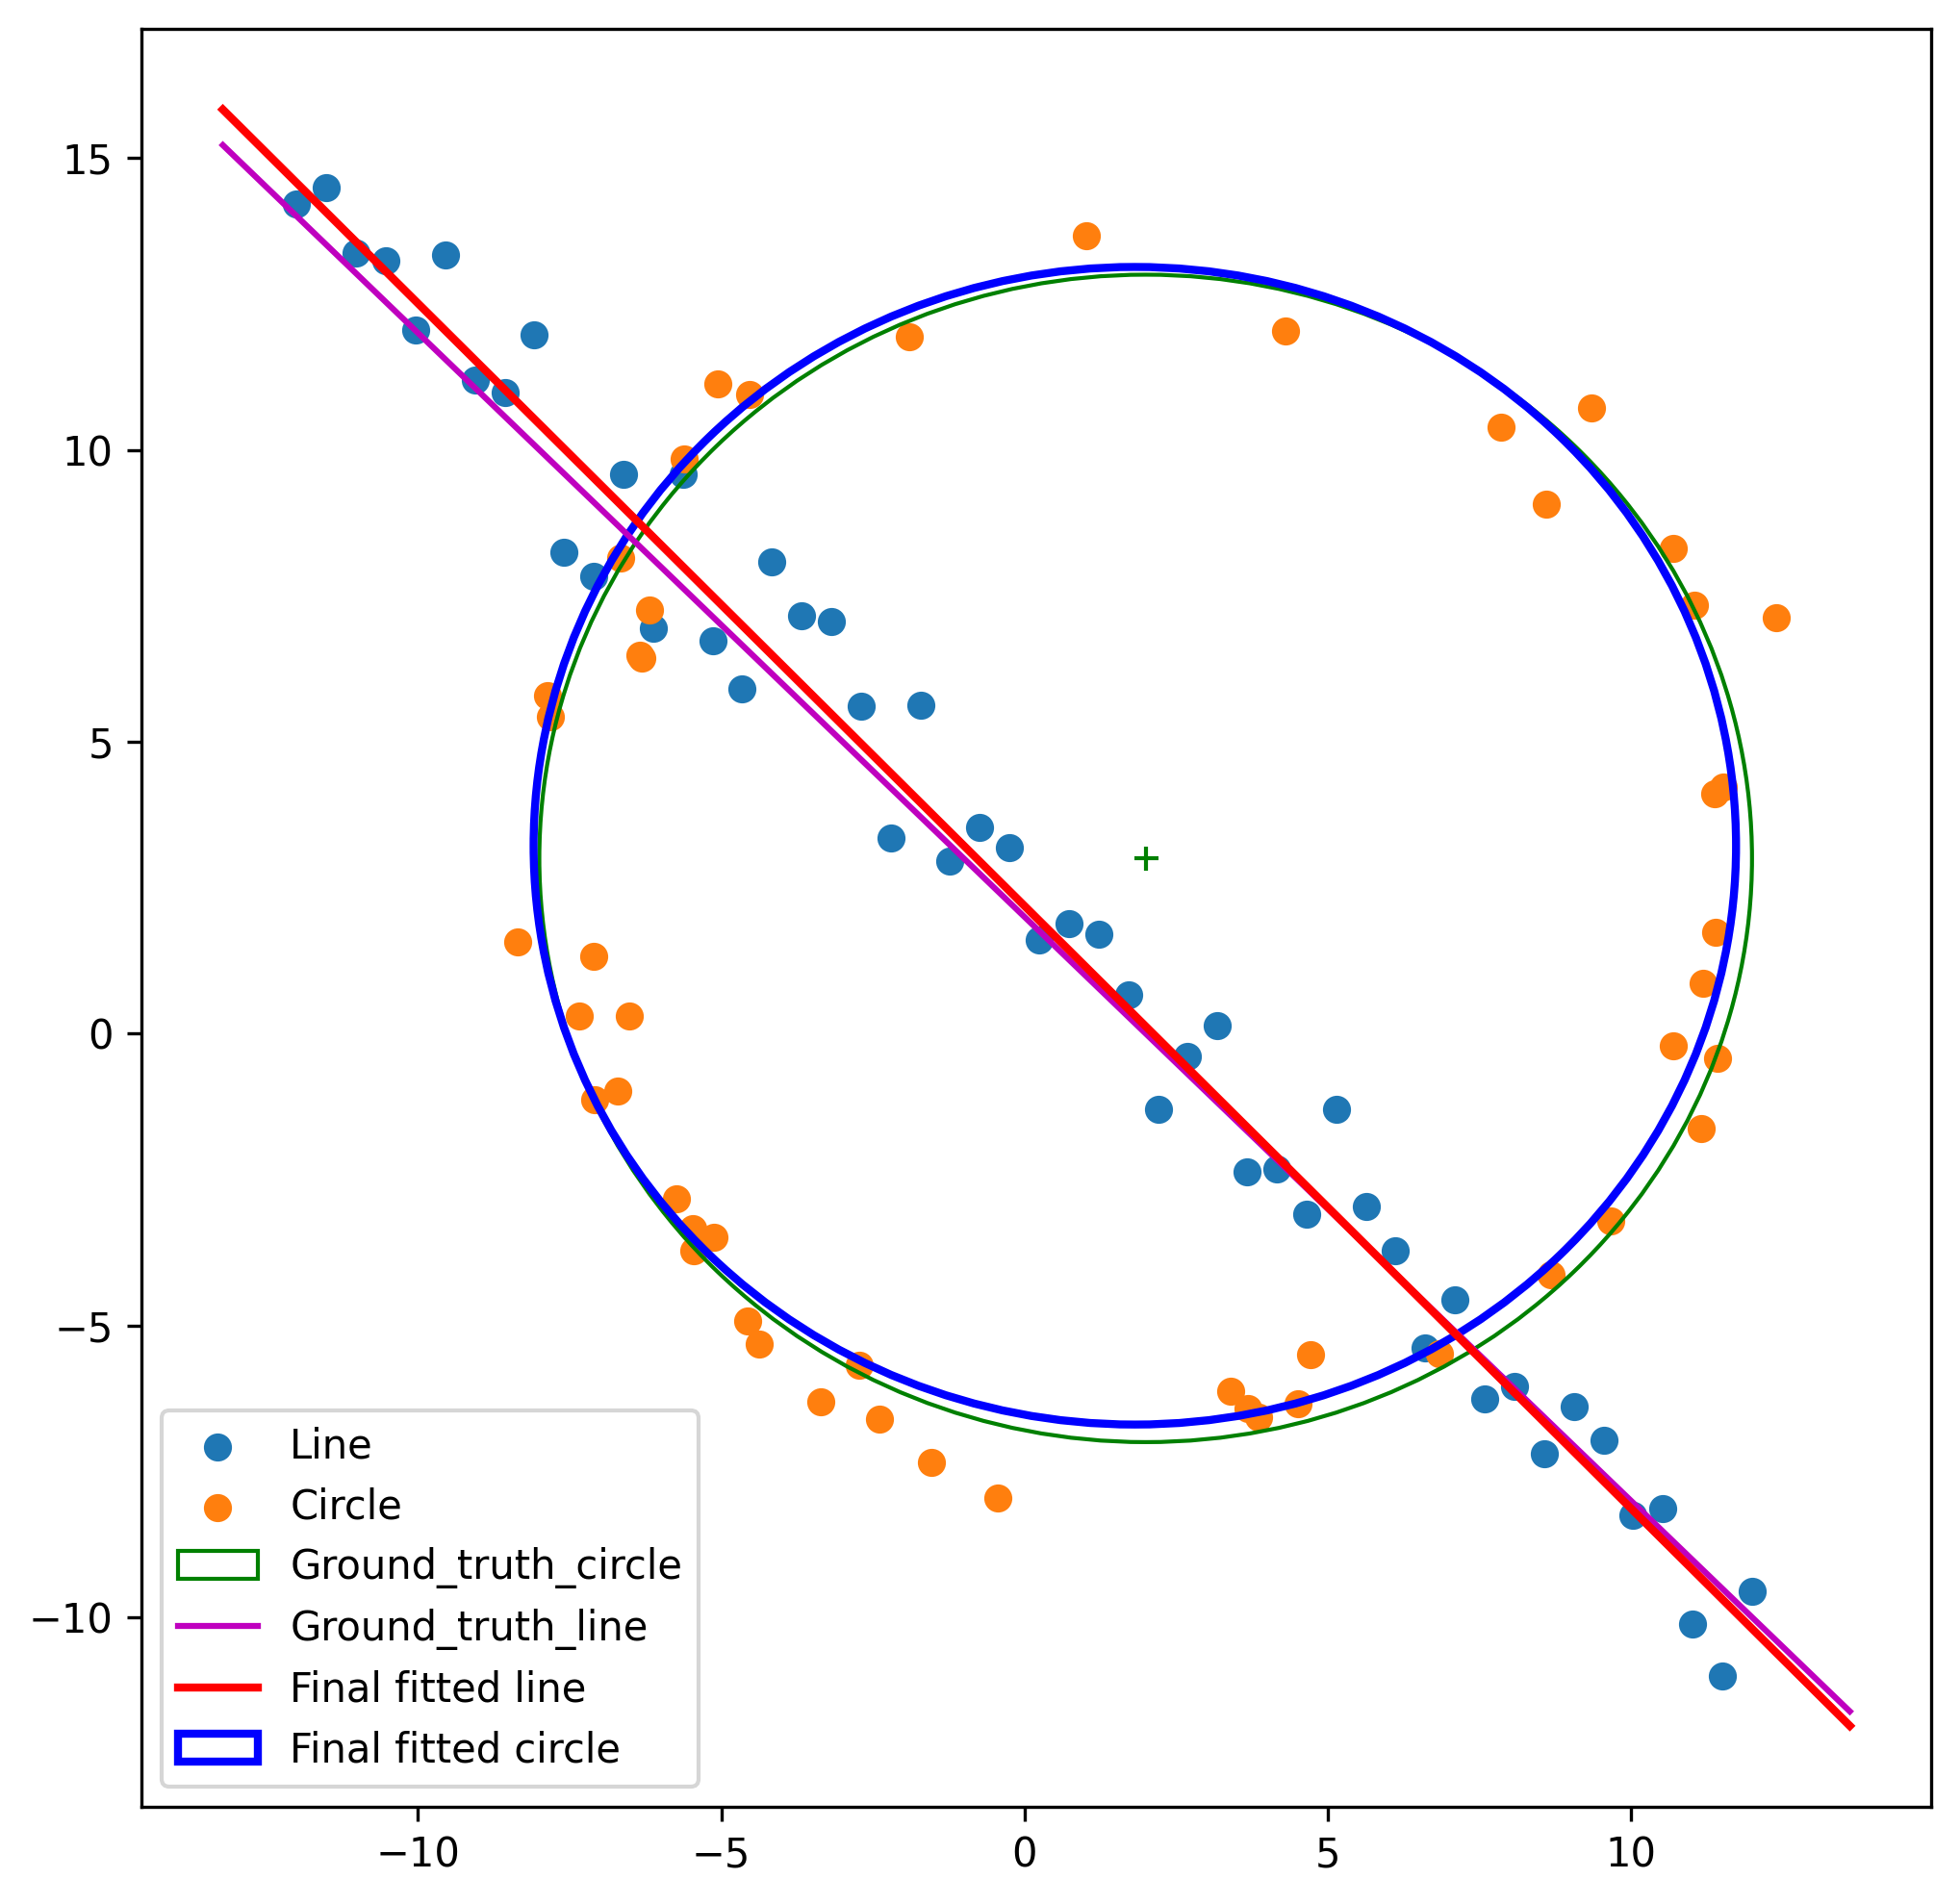

In [ ]:
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt
import numpy as np

np.random.seed(0)
N = 100
half_n = N//2

r = 10
x0_gt, y0_gt = 2, 3  # Center
s = r/16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s*np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n,1), y.reshape(half_n,1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n,1), y.reshape(half_n,1)))
X = np.vstack((X_circ, X_line))  # All points

fig, ax = plt.subplots(1,1, figsize=(8,8), dpi=300)
ax.scatter(X_line[:,0], X_line[:,1], label='Line')
ax.scatter(X_circ[:,0], X_circ[:,1], label='Circle')
circle_gt = plt.Circle((x0_gt,y0_gt), r, color='g', fill=False, label='Ground_truth_circle')
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), '+', color='g')
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m*x_ + b
plt.plot(x_, y_, color='m', label='Ground_truth_line')
plt.legend()



# (a) RANSAC line fitting

def line_from_two_points(p1, p2):
    direction = p2 - p1

    if np.linalg.norm(direction) < 1e-10:
        return None

    # Unit normal perpendicular to the line direction
    normal = np.array([-direction[1], direction[0]])
    normal = normal / np.linalg.norm(normal)

    a_line, b_line = normal
    d_line = np.dot(normal, p1)

    return np.array([a_line, b_line, d_line])


def line_distances(points, line):
    a_line, b_line, d_line = line

    return np.abs(
        a_line * points[:, 0]
        + b_line * points[:, 1]
        - d_line
    )


def fit_line_tls(points):
    centroid = points.mean(axis=0)
    centered = points - centroid

    _, _, vh = linalg.svd(centered, full_matrices=False)

    normal = vh[-1]
    normal = normal / np.linalg.norm(normal)

    a_line, b_line = normal
    d_line = np.dot(normal, centroid)

    return np.array([a_line, b_line, d_line])


def ransac_line(points, iterations=3000, threshold=1.5,
                min_inliers=30):
    best_model = None
    best_inliers = None
    best_sample = None
    best_count = 0

    for _ in range(iterations):
        # Randomly choose two points
        indices = np.random.choice(len(points), 2, replace=False)
        sample = points[indices]

        model = line_from_two_points(sample[0], sample[1])

        if model is None:
            continue

        distances = line_distances(points, model)
        inliers = distances < threshold
        count = np.count_nonzero(inliers)

        if count > best_count:
            best_count = count
            best_model = model
            best_inliers = inliers
            best_sample = sample.copy()

    if best_model is None or best_count < min_inliers:
        raise RuntimeError("RANSAC could not find a suitable line.")

    # Refine the line using total least squares
    best_model = fit_line_tls(points[best_inliers])

    # Recalculate consensus after refinement
    refined_inliers = (
        line_distances(points, best_model) < threshold
    )

    if np.count_nonzero(refined_inliers) >= min_inliers:
        best_inliers = refined_inliers

    return best_model, best_inliers, best_sample


best_line, line_inliers, best_line_sample = ransac_line(
    X,
    iterations=3000,
    threshold=1.5,
    min_inliers=30
)

print("Line inliers:", np.count_nonzero(line_inliers))
print("Best-fit line [a, b, d]:", best_line)
print("Normal vector length:", np.linalg.norm(best_line[:2]))



#Remove line inliers and run RANSAC for a circle
X_remaining = X[~line_inliers]


def circle_from_three_points(p1, p2, p3):
    """Find the circle passing through three points."""
    matrix = 2 * np.array([
        p2 - p1,
        p3 - p1
    ])

    rhs = np.array([
        np.dot(p2, p2) - np.dot(p1, p1),
        np.dot(p3, p3) - np.dot(p1, p1)
    ])

    if abs(np.linalg.det(matrix)) < 1e-8:
        return None

    center = np.linalg.solve(matrix, rhs)
    radius = np.linalg.norm(center - p1)

    if not np.isfinite(radius) or radius <= 0:
        return None

    return np.array([center[0], center[1], radius])


def circle_radial_errors(points, circle):
    x0, y0, radius = circle

    distances = np.sqrt(
        (points[:, 0] - x0) ** 2
        + (points[:, 1] - y0) ** 2
    )

    return np.abs(distances - radius)


def ransac_circle(points, iterations=5000, threshold=0.8,
                  min_inliers=30):
    best_model = None
    best_inliers = None
    best_sample = None
    best_count = 0

    for _ in range(iterations):
        # Randomly choose three points
        indices = np.random.choice(len(points), 3, replace=False)
        sample = points[indices]

        model = circle_from_three_points(
            sample[0], sample[1], sample[2]
        )

        if model is None:
            continue

        errors = circle_radial_errors(points, model)
        inliers = errors < threshold
        count = np.count_nonzero(inliers)

        if count > best_count:
            best_count = count
            best_model = model
            best_inliers = inliers
            best_sample = sample.copy()

    if best_model is None or best_count < min_inliers:
        raise RuntimeError("RANSAC could not find a suitable circle.")

    return best_model, best_inliers, best_sample


sample_circle_model, circle_inliers, best_circle_sample = (
    ransac_circle(
        X_remaining,
        iterations=5000,
        threshold=0.8,
        min_inliers=30
    )
)

print("Circle RANSAC inliers:", np.count_nonzero(circle_inliers))
print("Circle from best sample:", sample_circle_model)



# Refine the circle using scipy.optimize.minimize
circle_points = X_remaining[circle_inliers]


def circle_objective(params, points):
    x0, y0, radius = params

    if radius <= 0:
        return 1e12

    distances = np.sqrt(
        (points[:, 0] - x0) ** 2
        + (points[:, 1] - y0) ** 2
    )

    residuals = distances - radius
    return np.sum(residuals ** 2)


result = minimize(
    circle_objective,
    sample_circle_model,
    args=(circle_points,),
    method='Nelder-Mead',
    options={
        'maxiter': 10000,
        'xatol': 1e-9,
        'fatol': 1e-9
    }
)

if not result.success:
    print("Optimizer warning:", result.message)

best_circle = result.x

# Update circle consensus using the refined circle
refined_circle_inliers = (
    circle_radial_errors(X_remaining, best_circle) < 0.8
)

if np.count_nonzero(refined_circle_inliers) >= 30:
    circle_inliers = refined_circle_inliers

print("Final circle [x0, y0, radius]:", best_circle)
print("Final circle inliers:", np.count_nonzero(circle_inliers))


# Final best-fit line
a_line, b_line, d_line = best_line

x_final = np.array([x_min, x_max])

if abs(b_line) > 1e-10:
    y_final = (d_line - a_line * x_final) / b_line

    ax.plot(
        x_final,
        y_final,
        color='red',
        linewidth=2,
        label='Final fitted line'
    )
else:
    ax.axvline(
        d_line / a_line,
        color='red',
        linewidth=2,
        label='Final fitted line'
    )

# Final best-fit circle
x0_final, y0_final, r_final = best_circle

circle_final = plt.Circle(
    (x0_final, y0_final),
    r_final,
    color='blue',
    fill=False,
    linewidth=2,
    label='Final fitted circle'
)

ax.add_patch(circle_final)

# Show the final plot
ax.legend()
plt.show()


If we fit the circle first, RANSAC will try to identify the circle's inliers from the entire dataset of 100 points, including both the 50 circle points and the 50 line points.
- Potential problem: Some points belonging to the line may accidentally lie close to a candidate circle and be classified as inliers.
- Circle fitting: RANSAC selects the circle with the largest number of inliers, so it may still find the correct circle if the circle points form a sufficiently strong consensus.
- Then fit the line: After identifying the circle, we remove its inliers and run line RANSAC on the remaining points.
Conclusion: Fitting the circle first can also work, but the result depends on the noise, thresholds, and how well each shape's points are separated. Ideally, both approaches should recover the correct line and circle when the models are sufficiently distinct.

# Question 3